# Feature Interactions Under Distribution Shift

## Consolidated, reproducible experiment workflow

**Research question:** How do individual and combined changes in input-feature distributions affect the measured performance of machine-learning models?

This notebook evaluates fixed models on the Adult test set using **class-preserving subgroup reweighting**. Selected records receive larger evaluation weights, while the total weight assigned to each income class remains unchanged. This is an evaluation-distribution sensitivity analysis; it does **not** simulate retraining on a new population or establish real-world performance under every possible shift.

**Before running:** place this notebook in the same folder as `adult.data` and `adult.test`, then run all cells from top to bottom.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report

RANDOM_STATE = 42
DATA_DIR = Path.cwd()

print("scikit-learn:", sklearn.__version__)
print("Working folder:", DATA_DIR)
for filename in ["adult.data", "adult.test"]:
    if not (DATA_DIR / filename).exists():
        raise FileNotFoundError(f"Could not find {filename} in {DATA_DIR}. Open/run this notebook from your project folder.")

scikit-learn: 1.9.0
Working folder: C:\Users\DELL\OneDrive\Documents\Research Project (Feature Interaction 2)


## 1. Load and inspect the data

The official test file includes a header-like comment and income labels ending in periods; this cell handles both.

C:\Users\DELL\AppData\Local\Temp\ipykernel_5060\198234228.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in data.select_dtypes(include="object").columns:
C:\Users\DELL\AppData\Local\Temp\ipykernel_5060\198234228.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/mi

Training shape: (32561, 15)
Test shape: (16281, 15)
Training missing values:


,missing_count
age,0
workclass,1836
fnlwgt,0
education,0
education_num,0
marital_status,0
occupation,1843
relationship,0
race,0
sex,0


Training labels:


income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Test labels:


income
<=50K    12435
>50K      3846
Name: count, dtype: int64

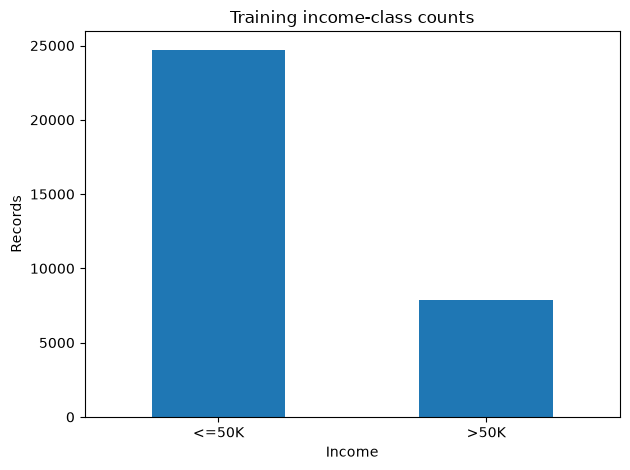

In [2]:
columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

train_df = pd.read_csv(DATA_DIR / "adult.data", names=columns, skipinitialspace=True, na_values="?", skip_blank_lines=True)
test_df = pd.read_csv(DATA_DIR / "adult.test", names=columns, skipinitialspace=True, na_values="?", comment="|", skip_blank_lines=True)

for data in (train_df, test_df):
    for col in data.select_dtypes(include="object").columns:
        data[col] = data[col].str.strip()
    data["income"] = data["income"].str.rstrip(".")

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Training missing values:")
display(train_df.isna().sum().to_frame("missing_count"))
print("Training labels:")
display(train_df["income"].value_counts())
print("Test labels:")
display(test_df["income"].value_counts())

train_df["income"].value_counts().plot(kind="bar", title="Training income-class counts", xlabel="Income", ylabel="Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Define preprocessing and models

Preprocessing is fitted on training data only, preventing information from the test set from being used to fit imputers, scaling, or category encoders.

In [3]:
X_train = train_df.drop(columns="income")
y_train = train_df["income"]
X_test = test_df.drop(columns="income")
y_test = test_df["income"]

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

model_definitions = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
}

fitted_models = {}
predictions_by_model = {}
baseline_rows = []
for model_name, classifier in model_definitions.items():
    model = Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    fitted_models[model_name] = model
    predictions_by_model[model_name] = predictions
    baseline_rows.append({
        "model": model_name,
        "experiment": "Baseline",
        "multiplier": 1,
        "accuracy": accuracy_score(y_test, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_test, predictions)
    })

baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df.round(4))
print("Logistic Regression classification report:")
print(classification_report(y_test, predictions_by_model["Logistic Regression"]))

C:\Users\DELL\AppData\Local\Temp\ipykernel_5060\3329655157.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(include="object").columns.tolist()


,model,experiment,multiplier,accuracy,balanced_accuracy
0,Logistic Regression,Baseline,1,0.8507,0.7597
1,Decision Tree,Baseline,1,0.8127,0.7441
2,Random Forest,Baseline,1,0.8509,0.7673


Logistic Regression classification report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91     12435
        >50K       0.73      0.59      0.65      3846

    accuracy                           0.85     16281
   macro avg       0.80      0.76      0.78     16281
weighted avg       0.84      0.85      0.84     16281



## 3. Define single-feature and combined-feature subgroups

These masks identify which test records receive extra weight. They are operational definitions for this experiment, not universal definitions of distribution shift.

In [4]:
shift_masks = {
    "Age": X_test["age"] >= 40,
    "Hours": X_test["hours_per_week"] > 45,
    "Education": X_test["education_num"] > 12,
    "Age+Hours": (X_test["age"] >= 40) & (X_test["hours_per_week"] > 45),
    "Age+Education": (X_test["age"] >= 40) & (X_test["education_num"] > 12),
    "Hours+Education": (X_test["hours_per_week"] > 45) & (X_test["education_num"] > 12),
    "Age+Hours+Education": (X_test["age"] >= 40) & (X_test["hours_per_week"] > 45) & (X_test["education_num"] > 12)
}

mask_summary = pd.DataFrame([
    {"experiment": name, "selected_records": int(mask.sum()), "test_records": len(mask), "selected_fraction": float(mask.mean())}
    for name, mask in shift_masks.items()
])
display(mask_summary.round(4))

,experiment,selected_records,test_records,selected_fraction
0,Age,7161,16281,0.4398
1,Hours,3562,16281,0.2188
2,Education,4043,16281,0.2483
3,Age+Hours,1814,16281,0.1114
4,Age+Education,2080,16281,0.1278
5,Hours+Education,1319,16281,0.0810
6,Age+Hours+Education,735,16281,0.0451


## 4. Weighting method and validation

For each income class separately, selected subgroup records get a multiplier and all weights in that class are then rescaled so the class's total weight equals its original record count. Therefore, the weighted income-class proportions stay unchanged while the subgroup's influence within each class changes.

In [5]:
def make_class_preserving_weights(mask, labels, multiplier=3):
    """Upweight selected rows while preserving each class's total weight."""
    if multiplier < 1:
        raise ValueError("multiplier must be >= 1")
    mask = np.asarray(mask, dtype=bool)
    labels = np.asarray(labels)
    if len(mask) != len(labels):
        raise ValueError("mask and labels must have the same length")

    weights = np.where(mask, float(multiplier), 1.0)
    for label in np.unique(labels):
        class_indices = labels == label
        weights[class_indices] *= class_indices.sum() / weights[class_indices].sum()
    return weights

# Sanity check: at multiplier=1, weights are all equal to 1.
weights_one = make_class_preserving_weights(np.asarray(shift_masks["Education"]), y_test, multiplier=1)
assert np.allclose(weights_one, 1.0)

# Check that class proportions remain unchanged under a nontrivial weighting.
weights_check = make_class_preserving_weights(shift_masks["Education"], y_test, multiplier=3)
original_class_proportions = y_test.value_counts(normalize=True).sort_index()
weighted_class_proportions = pd.Series({
    label: weights_check[np.asarray(y_test == label)].sum() / weights_check.sum()
    for label in original_class_proportions.index
}).sort_index()
print("Original class proportions:")
display(original_class_proportions.round(4))
print("Weighted class proportions (should match):")
display(weighted_class_proportions.round(4))
assert np.allclose(original_class_proportions.values, weighted_class_proportions.values)
print("Weighting checks passed.")

Original class proportions:


income
<=50K    0.7638
>50K     0.2362
Name: proportion, dtype: float64

Weighted class proportions (should match):


<=50K    0.7638
>50K     0.2362
dtype: float64

Weighting checks passed.


## 5. Evaluate single and combined shifts across models

Models are trained once on the original training set. We then hold their predictions fixed and recompute weighted evaluation metrics for each subgroup.

In [6]:
all_shift_rows = []
for model_name, predictions in predictions_by_model.items():
    for experiment_name, mask in shift_masks.items():
        weights = make_class_preserving_weights(mask, y_test, multiplier=3)
        all_shift_rows.append({
            "model": model_name,
            "experiment": experiment_name,
            "multiplier": 3,
            "accuracy": accuracy_score(y_test, predictions, sample_weight=weights),
            "balanced_accuracy": balanced_accuracy_score(y_test, predictions, sample_weight=weights)
        })

all_shift_df = pd.concat([baseline_df, pd.DataFrame(all_shift_rows)], ignore_index=True)
base_lookup = baseline_df.set_index("model")["balanced_accuracy"]
all_shift_df["baseline_balanced_accuracy"] = all_shift_df["model"].map(base_lookup)
all_shift_df["balanced_accuracy_change_pp"] = (all_shift_df["balanced_accuracy"] - all_shift_df["baseline_balanced_accuracy"]) * 100

display(all_shift_df.round(4))
all_shift_df.to_csv(DATA_DIR / "consolidated_shift_results.csv", index=False)
print("Saved consolidated_shift_results.csv")

,model,experiment,multiplier,accuracy,balanced_accuracy,baseline_balanced_accuracy,balanced_accuracy_change_pp
0,Logistic Regression,Baseline,1,0.8507,0.7597,0.7597,0.0000
1,Decision Tree,Baseline,1,0.8127,0.7441,0.7441,0.0000
2,Random Forest,Baseline,1,0.8509,0.7673,0.7673,0.0000
3,Logistic Regression,Age,3,0.8414,0.7628,0.7597,0.3095
4,Logistic Regression,Hours,3,0.8402,0.7680,0.7597,0.8330
5,Logistic Regression,Education,3,0.8477,0.8004,0.7597,4.0714
6,Logistic Regression,Age+Hours,3,0.8439,0.7721,0.7597,1.2442
7,Logistic Regression,Age+Education,3,0.8522,0.8001,0.7597,4.0454
8,Logistic Regression,Hours+Education,3,0.8538,0.7917,0.7597,3.2061
9,Logistic Regression,Age+Hours+Education,3,0.8562,0.7879,0.7597,2.8247


Saved consolidated_shift_results.csv


## 6. Test different Education-shift strengths

The multiplier controls how strongly selected Education-subgroup records influence the evaluation, after class totals are normalized. This is a sensitivity analysis, not a change to the trained model.

In [7]:
strength_rows = []
education_mask = shift_masks["Education"]
for model_name, predictions in predictions_by_model.items():
    baseline = baseline_df.loc[baseline_df["model"] == model_name].iloc[0]
    strength_rows.append({
        "model": model_name, "experiment": "Baseline", "multiplier": 1,
        "accuracy": baseline["accuracy"],
        "balanced_accuracy": baseline["balanced_accuracy"]
    })
    for multiplier in [1, 2, 3, 5]:
        weights = make_class_preserving_weights(education_mask, y_test, multiplier=multiplier)
        strength_rows.append({
            "model": model_name, "experiment": "Education", "multiplier": multiplier,
            "accuracy": accuracy_score(y_test, predictions, sample_weight=weights),
            "balanced_accuracy": balanced_accuracy_score(y_test, predictions, sample_weight=weights)
        })

strength_df = pd.DataFrame(strength_rows)
strength_baselines = baseline_df.set_index("model")["balanced_accuracy"]
strength_df["baseline_balanced_accuracy"] = strength_df["model"].map(strength_baselines)
strength_df["balanced_accuracy_change_pp"] = (strength_df["balanced_accuracy"] - strength_df["baseline_balanced_accuracy"]) * 100
display(strength_df.round(4))
strength_df.to_csv(DATA_DIR / "education_strength_results.csv", index=False)
print("Saved education_strength_results.csv")

,model,experiment,multiplier,accuracy,balanced_accuracy,baseline_balanced_accuracy,balanced_accuracy_change_pp
0,Logistic Regression,Baseline,1,0.8507,0.7597,0.7597,0.0000
1,Logistic Regression,Education,1,0.8507,0.7597,0.7597,0.0000
2,Logistic Regression,Education,2,0.8517,0.7887,0.7597,2.9073
3,Logistic Regression,Education,3,0.8477,0.8004,0.7597,4.0714
4,Logistic Regression,Education,5,0.8383,0.8085,0.7597,4.8887
5,Decision Tree,Baseline,1,0.8127,0.7441,0.7441,0.0000
6,Decision Tree,Education,1,0.8127,0.7441,0.7441,0.0000
7,Decision Tree,Education,2,0.8102,0.7574,0.7441,1.3334
8,Decision Tree,Education,3,0.8058,0.7621,0.7441,1.7999
9,Decision Tree,Education,5,0.7978,0.7644,0.7441,2.0270


Saved education_strength_results.csv


## 7. Plot the Education-strength sensitivity analysis

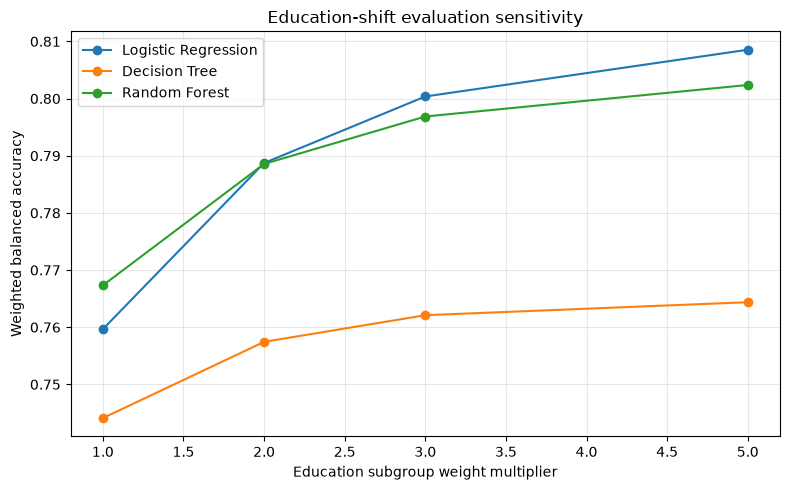

Saved education_strength_graph.png


In [8]:
plt.figure(figsize=(8, 5))
for model_name in strength_df["model"].unique():
    subset = strength_df[(strength_df["model"] == model_name) & (strength_df["experiment"] == "Education")].sort_values("multiplier")
    plt.plot(subset["multiplier"], subset["balanced_accuracy"], marker="o", label=model_name)
plt.xlabel("Education subgroup weight multiplier")
plt.ylabel("Weighted balanced accuracy")
plt.title("Education-shift evaluation sensitivity")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(DATA_DIR / "education_strength_graph.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved education_strength_graph.png")

## 8. Results interpretation and limitations

When all cells run successfully, retain the generated CSVs and graph. Interpret the results as **sensitivity of fixed models' metrics to class-preserving subgroup reweighting**. A score increase is not proof that the model improved, nor proof that it will perform better on a genuinely shifted future population.

Important limitations to discuss:
- The subgroup cutoffs (age >= 40, hours > 45, education number > 12) are chosen operationally and need justification or sensitivity checks.
- This is one dataset and one fixed train/test split.
- No uncertainty intervals or repeated-split estimates are included in this initial workflow.
- Subgroup reweighting is not equivalent to collecting a new shifted dataset or retraining on it.
- The Adult dataset is historical and has known representativeness and fairness concerns.

**Do not claim novelty yet.** A literature review is needed before making a novelty claim.